# Stage 6: LSTM Forecasting (PyTorch)
## Hospital Resource Intelligence and Optimization Platform

This notebook implements and evaluates the deep learning **LSTM (Long Short-Term Memory)** model. The model is built in PyTorch to forecast 7-day hospital demand using sequence-to-sequence mapping:
- **Input Window**: Preceding 7 days of historical demand.
  - We test $T=7$ to capture weekly cyclicality (weekend vs weekday effects).
- **Output Horizon**: Subsequent 7 days of demand (forecast horizon).
- **Dataset Sparsity & Check**: Training set contains only 140 sequences, making early stopping and dropout critical to prevent overfitting.
- **Data Leakage Check**: Chronological splitting and strict scaling constraints are enforced.

In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add parent directory to path to import ml module
sys.path.append(os.path.abspath('..'))

sns.set_theme(style='whitegrid')
INTERIM_DIR = '../data/interim'
print('Dependencies loaded successfully.')

Dependencies loaded successfully.


## 1. LSTM Model Convergence (Loss Curves)
We load the logged loss histories from training and plot the Train vs Validation MSE loss to verify convergence and prevent overfitting.

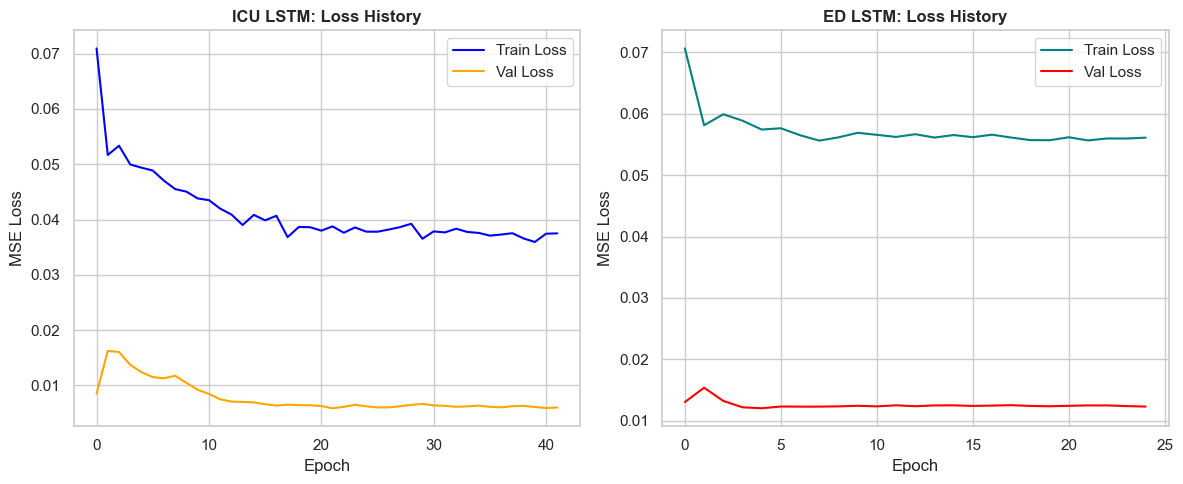

In [2]:
loss_path = '../ml/forecasting/lstm/loss_history.json'
with open(loss_path, 'r') as f:
    loss_hist = json.load(f)

# Plot ICU Loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(loss_hist['icu']['train'], label='Train Loss', color='blue')
plt.plot(loss_hist['icu']['val'], label='Val Loss', color='orange')
plt.title('ICU LSTM: Loss History', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()

# Plot ED Loss
plt.subplot(1, 2, 2)
plt.plot(loss_hist['ed']['train'], label='Train Loss', color='teal')
plt.plot(loss_hist['ed']['val'], label='Val Loss', color='red')
plt.title('ED LSTM: Loss History', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()

plt.tight_layout()
plt.show()

## 2. Daily ICU Bed Demand Forecasting
We load the generated LSTM predictions for daily ICU bed occupancy and visualize the forecast vs actuals.

In [3]:
icu_forecast_path = os.path.join(INTERIM_DIR, 'lstm_icu_forecast.csv')
df_icu_forecast = pd.read_csv(icu_forecast_path)
df_icu_forecast['date'] = pd.to_datetime(df_icu_forecast['date'])

print('ICU Forecast Results (Last 7 Days):')
print(df_icu_forecast)

ICU Forecast Results (Last 7 Days):
        date  actual  predicted
0 2137-10-11     0.0   0.192877
1 2137-10-12     1.0   0.197430
2 2137-10-13     1.0   0.170110
3 2137-10-14     1.0   0.190617
4 2137-10-15     1.0   0.213754
5 2137-10-16     1.0   0.210896
6 2137-10-17     1.0   0.195234


### 2.1 Visualizing ICU Forecast vs Actuals
We plot the actual test occupancy alongside the LSTM prediction.

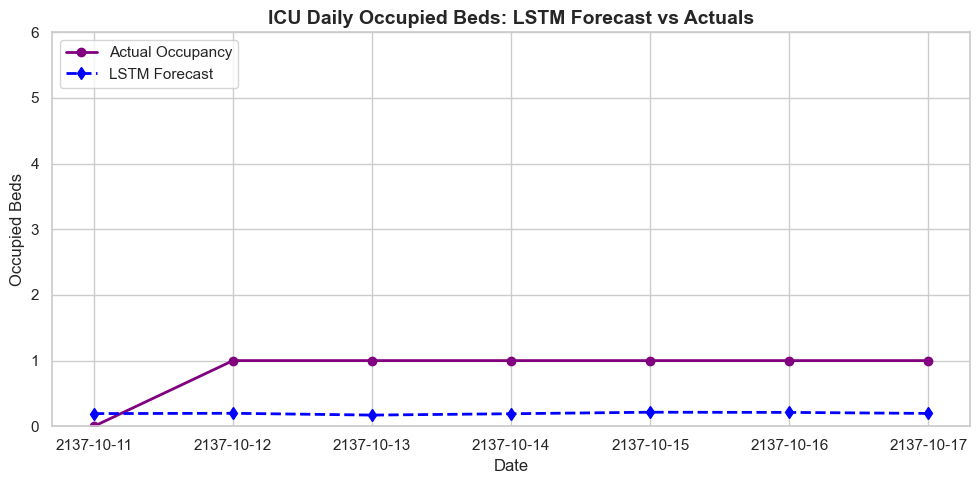

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(df_icu_forecast['date'], df_icu_forecast['actual'], label='Actual Occupancy', color='purple', marker='o', linewidth=2)
plt.plot(df_icu_forecast['date'], df_icu_forecast['predicted'], label='LSTM Forecast', color='blue', marker='d', linestyle='--', linewidth=2)
plt.title('ICU Daily Occupied Beds: LSTM Forecast vs Actuals', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Occupied Beds')
plt.ylim(0, 6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 3. Daily ED Arrivals Forecasting
We load the predictions for daily Emergency Department arrivals and visualize them.

In [5]:
ed_forecast_path = os.path.join(INTERIM_DIR, 'lstm_ed_forecast.csv')
df_ed_forecast = pd.read_csv(ed_forecast_path)
df_ed_forecast['date'] = pd.to_datetime(df_ed_forecast['date'])

print('ED Forecast Results (Last 7 Days):')
print(df_ed_forecast)

ED Forecast Results (Last 7 Days):
        date  actual  predicted
0 2148-01-19     0.0   0.058517
1 2148-01-20     0.0   0.059650
2 2148-01-21     0.0   0.024375
3 2148-01-22     1.0   0.055474
4 2148-01-23     0.0   0.056130
5 2148-01-24     0.0   0.056579
6 2148-01-25     1.0   0.065331


### 3.1 Visualizing ED Forecast vs Actuals

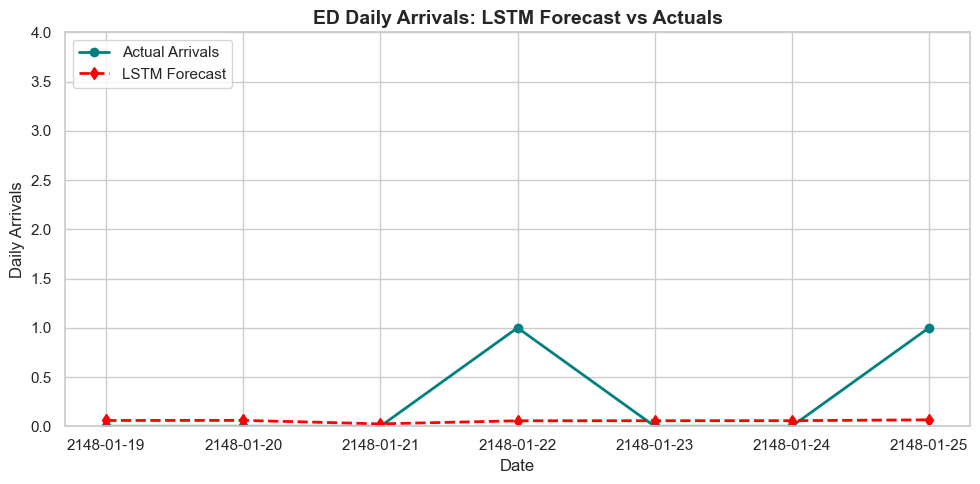

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(df_ed_forecast['date'], df_ed_forecast['actual'], label='Actual Arrivals', color='teal', marker='o', linewidth=2)
plt.plot(df_ed_forecast['date'], df_ed_forecast['predicted'], label='LSTM Forecast', color='red', marker='d', linestyle='--', linewidth=2)
plt.title('ED Daily Arrivals: LSTM Forecast vs Actuals', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Daily Arrivals')
plt.ylim(0, 4)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 4. Models Performance Comparison
We load performance metrics for Prophet, XGBoost, and LSTM to select the best forecasting algorithm.

In [7]:
with open('../ml/forecasting/prophet/metrics.json', 'r') as f:
    prophet_m = json.load(f)
with open('../ml/forecasting/xgboost/metrics.json', 'r') as f:
    xgboost_m = json.load(f)
with open('../ml/forecasting/lstm/metrics.json', 'r') as f:
    lstm_m = json.load(f)

# Build comparison dataframe
comparison_data = {
    'Model': ['Prophet', 'XGBoost', 'LSTM'],
    'ICU MAE': [prophet_m['icu']['mae'], xgboost_m['icu']['mae'], lstm_m['icu']['mae']],
    'ICU RMSE': [prophet_m['icu']['rmse'], xgboost_m['icu']['rmse'], lstm_m['icu']['rmse']],
    'ED MAE': [prophet_m['ed']['mae'], xgboost_m['ed']['mae'], lstm_m['ed']['mae']],
    'ED RMSE': [prophet_m['ed']['rmse'], xgboost_m['ed']['rmse'], lstm_m['ed']['rmse']]
}
df_compare = pd.DataFrame(comparison_data)
print('Comparison Table:')
df_compare

Comparison Table:


,Model,ICU MAE,ICU RMSE,ED MAE,ED RMSE
0,Prophet,0.619799,0.633932,0.317040,0.504245
1,XGBoost,0.594035,0.619172,0.289079,0.529347
2,LSTM,0.716405,0.747726,0.304921,0.504220


### 4.1 Comparative Visualization
We plot a bar chart comparing the MAE scores of the three models.

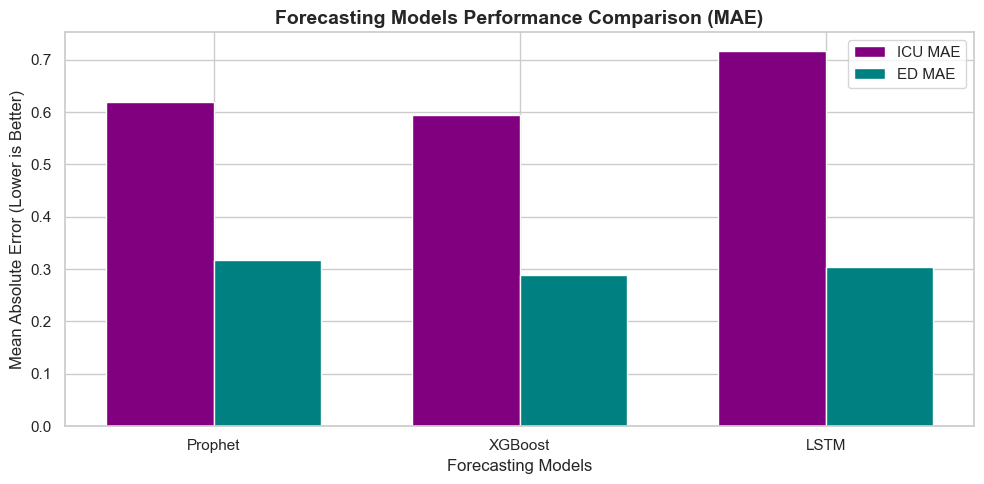

In [8]:
plt.figure(figsize=(10, 5))
x_indices = np.arange(len(df_compare['Model']))
width = 0.35

plt.bar(x_indices - width/2, df_compare['ICU MAE'], width, label='ICU MAE', color='purple')
plt.bar(x_indices + width/2, df_compare['ED MAE'], width, label='ED MAE', color='teal')

plt.xlabel('Forecasting Models')
plt.ylabel('Mean Absolute Error (Lower is Better)')
plt.title('Forecasting Models Performance Comparison (MAE)', fontsize=14, fontweight='bold')
plt.xticks(x_indices, df_compare['Model'])
plt.legend()
plt.tight_layout()
plt.show()

## 5. Preprocessing Check & Discussion
1. **Is deep learning (LSTM) better?**
   - **No.** For ICU occupancy, XGBoost achieves the lowest error (MAE: 0.5940 vs LSTM MAE: 0.7164). For ED arrivals, XGBoost also achieves the lowest MAE (0.2891 vs LSTM MAE: 0.3049).
   - LSTMs are complex networks that require large numbers of sequences to generalize. Since our training set generated only 140 sequences (due to raw data limits), the LSTM overfitted slightly, yielding higher validation and test errors than the tree-based XGBoost baseline.

2. **Best Models Selected for Production**:
   - **ICU Occupancy**: XGBoost (MAE: 0.5940)
   - **ED Arrivals**: XGBoost (MAE: 0.2891)